# DNN Programming Assignment 2 — Problem 2: Transformer from Scratch

**Student Name:** Anand Shah  

**Student ID:** 2026AJ05251

**Chosen Variants:**
- Model Width $d = 128$
- Heads $H = 4$ ($d_k = 32$)
- $d_{ff} = 512$
- Random Seeds: 42, 43, 44  


In [1]:
import os
import sys
import time
import math
import random
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure reproducibility and configure threads
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
torch.set_num_threads(8)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}, PyTorch threads: {torch.get_num_threads()}")


# Helper to log experiment results directly to results.csv
RESULTS_CSV_PATH = os.path.join(os.path.dirname(os.path.abspath('')), 'results.csv')
if not os.path.exists(RESULTS_CSV_PATH):
    RESULTS_CSV_PATH = 'results.csv'

def log_result(problem, model, seed, seq_len=None, test_acc=None, macro_f1=None,
               test_mse=None, params=None, sec_per_epoch=None, val_loss_nats=None,
               bits_per_char=None, notes=""):
    """Appends or updates a row in results.csv matching the assignment specification."""
    row = {
        'problem': problem,
        'model': model,
        'seed': seed,
        'seq_len': '' if seq_len is None else seq_len,
        'test_acc': f"{test_acc:.4f}" if test_acc is not None else '',
        'macro_f1': f"{macro_f1:.4f}" if macro_f1 is not None else '',
        'test_mse': f"{test_mse:.5f}" if test_mse is not None else '',
        'params': '' if params is None else params,
        'sec_per_epoch': f"{sec_per_epoch:.2f}" if sec_per_epoch is not None else '',
        'val_loss_nats': f"{val_loss_nats:.4f}" if val_loss_nats is not None else '',
        'bits_per_char': f"{bits_per_char:.4f}" if bits_per_char is not None else '',
        'notes': notes
    }
    header = "problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes\n"
    line = f"{row['problem']},{row['model']},{row['seed']},{row['seq_len']},{row['test_acc']},{row['macro_f1']},{row['test_mse']},{row['params']},{row['sec_per_epoch']},{row['val_loss_nats']},{row['bits_per_char']},\"{row['notes']}\"\n"

    if os.path.exists(RESULTS_CSV_PATH):
        with open(RESULTS_CSV_PATH, 'a', encoding='utf-8') as f:
            f.write(line)
    else:
        with open(RESULTS_CSV_PATH, 'w', encoding='utf-8') as f:
            f.write(header + line)


Executing on device: cpu, PyTorch threads: 8


## Task 2.1: Attention from scratch

Write scaled dot-product attention with an optional mask.
Unit tests must show that each row of weights sums to 1, that the output matches torch.nn.functional.scaled_dot_product_attention within 1e-5, and that a causal mask gives zero weight to future positions.


Include a hand-checkable 3-token example supplied by the instructor, computed by hand and by code.

In [ ]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """Scaled dot-product attention from scratch.
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask, float('-inf'))
    weights = F.softmax(scores, dim=-1)
    output = torch.matmul(weights, V)
    return output, weights

# Unit Tests against PyTorch F.scaled_dot_product_attention
B, H, T, d_k = 2, 4, 8, 32
Q = torch.randn(B, H, T, d_k)
K = torch.randn(B, H, T, d_k)
V = torch.randn(B, H, T, d_k)

# 1. Unmasked match
out_my, w_my = scaled_dot_product_attention(Q, K, V)
out_ref = F.scaled_dot_product_attention(Q, K, V)
diff_unmasked = (out_my - out_ref).abs().max().item()
assert diff_unmasked < 1e-5, f"Unmasked mismatch: {diff_unmasked}"

# 2. Probability simplex check
assert torch.allclose(w_my.sum(dim=-1), torch.ones_like(w_my.sum(dim=-1))), "Weights must sum to 1"

# 3. Causal masked match
causal_mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
out_my_c, w_my_c = scaled_dot_product_attention(Q, K, V, mask=causal_mask)
out_ref_c = F.scaled_dot_product_attention(Q, K, V, is_causal=True)
diff_causal = (out_my_c - out_ref_c).abs().max().item()
assert diff_causal < 1e-5, f"Causal mismatch: {diff_causal}"
assert torch.all(w_my_c.masked_select(causal_mask) == 0.0), "Future positions must have exactly zero attention"

print("Task 2.1 Unit Tests PASSED")
print(f"Unmasked diff={diff_unmasked:.2e}, Causal diff={diff_causal:.2e}")

Task 2.1 Unit Tests PASSED
Unmasked diff=3.58e-07, Causal diff=3.58e-07


### Hand-Checkable 3-Token Example ($d_k=2$)

Analytical manual calculation:

$Q = \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ 1 & 1 \end{pmatrix}, \quad K = \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ 0 & 1 \end{pmatrix}, \quad V = \begin{pmatrix} 1 & 2 \\ 3 & 4 \\ 5 & 6 \end{pmatrix}$

1. $S = \frac{Q K^T}{\sqrt{2}} = \begin{pmatrix} 0.7071 & 0 & 0 \\ 0 & 0.7071 & 0.7071 \\ 0.7071 & 0.7071 & 0.7071 \end{pmatrix}$

2. Softmax attention weights: $A = \begin{pmatrix} 0.4011 & 0.4011 & 0.1978 \\ 0.4011 & 0.1978 & 0.4011 \\ 0.5035 & 0.2483 & 0.2483 \end{pmatrix}$

3. Attention output: $\text{Output} = A V = \begin{pmatrix} \mathbf{2.5933} & \mathbf{3.5933} \\ \mathbf{3.0000} & \mathbf{4.0000} \\ \mathbf{2.4895} & \mathbf{3.4895} \end{pmatrix}$

In [3]:
Q_hand = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=torch.float32)
K_hand = torch.tensor([[1.0, 1.0], [1.0, 0.0], [0.0, 1.0]], dtype=torch.float32)
V_hand = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]], dtype=torch.float32)

out_hand, weights_hand = scaled_dot_product_attention(Q_hand, K_hand, V_hand)
print("Computed Attention Output:")
print(out_hand)
expected_hand = torch.tensor([[2.5933, 3.5933], [3.0000, 4.0000], [2.4895, 3.4895]])
assert torch.allclose(out_hand, expected_hand, atol=1e-4), "Hand check mismatch!"
print("")
print("Hand check PASSED")

Computed Attention Output:
tensor([[2.5933, 3.5933],
        [3.0000, 4.0000],
        [2.4895, 3.4895]])

Hand check PASSED


## Task 2.2: Multi-head attention and encoder block


- Implement multi-head attention with W_Q, W_K, W_V and W_O and head reshaping, a pre-LayerNorm encoder block with a feed-forward layer of width 4d, residual connections and dropout, and sinusoidal positional encoding.

- Derive the weight count 4d² + 2·d·d_ff per block and match it to sum(p.numel()).

- For d = 128 and d_ff = 512 the weights alone come to 196,608 per block; students reconcile the biases and LayerNorm parameters



In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=128, num_heads=4, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None, return_attention=False):
        B, T, C = x.shape
        Q = self.W_Q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_K(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_V(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        attn_out, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        attn_out = self.dropout(attn_out)
        out = attn_out.transpose(1, 2).contiguous().view(B, T, C)
        out = self.W_O(out)
        if return_attention:
            return out, weights
        return out

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model=128, num_heads=4, d_ff=512, dropout=0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.mha = MultiHeadAttention(d_model, num_heads, dropout=dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x, mask=None, return_attention=False):
        norm_x = self.ln1(x)
        if return_attention:
            attn_out, weights = self.mha(norm_x, mask=mask, return_attention=True)
        else:
            attn_out = self.mha(norm_x, mask=mask, return_attention=False)
        x = x + self.dropout1(attn_out)
        x = x + self.ffn(self.ln2(x))
        if return_attention:
            return x, weights
        return x

block = TransformerEncoderBlock(d_model=128, num_heads=4, d_ff=512)
total_block_params = sum(p.numel() for p in block.parameters())
print(f"Task 2.2 Parameter Verification: Total Block Parameters = {total_block_params}")
assert total_block_params == 198272, f"Expected 198,272, got {total_block_params}"
print("Parameter derivation verified successfully")

Task 2.2 Parameter Verification: Total Block Parameters = 198272
Parameter derivation verified successfully


## Task 2.3: Task A: encoder classifier on the HAR data


- Reuse the Problem 1 data.
- Embed each time step (or each patch of 8 steps), add a CLS token, and classify with the encoder.
- Compare accuracy, parameters and training time with the best Problem 1 model.
- Ablate positional information: none, sinusoidal and learned.


In [5]:
# Reusing HAR Data from Problem 1
import urllib.request
import zipfile
import os
import numpy as np
import matplotlib.pyplot as plt

# Path to UCI HAR dataset inside the extracted folder
har_base = os.path.join('har', 'UCI HAR Dataset')

# Download dataset if not already done and save it as har.zip
if not os.path.exists('har.zip'):
    print("Downloading dataset...")
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    urllib.request.urlretrieve(url, 'har.zip')

# Extract outer dataset if directory doesn't exist
if not os.path.exists('har'):
    print("Extracting outer dataset...")
    with zipfile.ZipFile('har.zip', 'r') as zip_ref:
        zip_ref.extractall('har')

# Extract the nested 'UCI HAR Dataset.zip' inside 'har' if it exists and hasn't been extracted yet
inner_zip_path = os.path.join('har', 'UCI HAR Dataset.zip')
if os.path.exists(inner_zip_path) and not os.path.exists(har_base):
    print("Extracting inner dataset...")
    with zipfile.ZipFile(inner_zip_path, 'r') as zip_ref:
        zip_ref.extractall('har')

channels = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z'
]

def load_har_split(split):
    sigs = [np.loadtxt(os.path.join(har_base, split, 'Inertial Signals', f'{ch}_{split}.txt')) for ch in channels]
    X = np.stack(sigs, axis=-1).astype(np.float32)  # Shape: (N, 128, 9)
    y = np.loadtxt(os.path.join(har_base, split, f'y_{split}.txt'), dtype=int) - 1  # 0-indexed (0..5)
    subj = np.loadtxt(os.path.join(har_base, split, f'subject_{split}.txt'), dtype=int)
    return X, y, subj

X_tr_raw, y_tr_raw, s_tr = load_har_split('train')
X_te_raw, y_te_raw, s_te = load_har_split('test')
train_subjects = np.unique(s_tr)
test_subjects = np.unique(s_te)
print(f"Loaded HAR raw data for Task A: Train {X_tr_raw.shape}, Test {X_te_raw.shape}")
print(f"Unique train subjects: {len(train_subjects)}, test subjects: {len(test_subjects)}")

Extracting outer dataset...
Extracting inner dataset...
Loaded HAR raw data for Task A: Train (7352, 128, 9), Test (2947, 128, 9)
Unique train subjects: 21, test subjects: 9


In [6]:
class PatchedHARTransformer(nn.Module):
    def __init__(self, d_model=128, num_heads=4, d_ff=512, num_layers=2, num_classes=6, pe_type='sinusoidal', patch_size=8):
        super().__init__()
        self.patch_size = patch_size
        self.num_patches = 128 // patch_size  # 16
        self.patch_proj = nn.Linear(patch_size * 9, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pe_type = pe_type

        seq_len = self.num_patches + 1  # 17
        if pe_type == 'learned':
            self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        elif pe_type == 'sinusoidal':
            pe = torch.zeros(seq_len, d_model)
            position = torch.arange(0, seq_len, dtype=torch.float).unsqueeze(1)
            div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term)
            self.register_buffer('pe', pe.unsqueeze(0))

        self.layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_ff, dropout=0.1) for _ in range(num_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        # x: (B, 128, 9)
        B = x.shape[0]
        x_patches = x.view(B, self.num_patches, self.patch_size * 9)
        x_emb = self.patch_proj(x_patches)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x_seq = torch.cat([cls_tokens, x_emb], dim=1)  # (B, 17, d_model)

        if self.pe_type == 'sinusoidal':
            x_seq = x_seq + self.pe
        elif self.pe_type == 'learned':
            x_seq = x_seq + self.pos_emb

        for layer in self.layers:
            x_seq = layer(x_seq)
        cls_out = self.ln_f(x_seq[:, 0, :])
        return self.head(cls_out)

def train_eval_har_transformer(pe_type, seed, epochs=10):
    """Trains and evaluates PatchedHARTransformer using subject-wise split exactly like Problem 1."""
    from sklearn.metrics import accuracy_score, f1_score
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    val_subjects = rng.choice(train_subjects, 4, replace=False)
    val_mask = np.isin(s_tr, val_subjects)

    # Subject-wise normalization
    X_train_sub = X_tr_raw[~val_mask]
    mu = X_train_sub.mean(axis=(0, 1), keepdims=True)
    sigma = X_train_sub.std(axis=(0, 1), keepdims=True) + 1e-8

    X_train = (X_tr_raw[~val_mask] - mu) / sigma
    y_train = y_tr_raw[~val_mask]
    X_test = (X_te_raw - mu) / sigma
    y_test = y_te_raw

    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
        batch_size=128, shuffle=True
    )
    test_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)),
        batch_size=256, shuffle=False
    )

    model = PatchedHARTransformer(pe_type=pe_type).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
    sec_per_ep = (time.time() - t0) / epochs

    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for bx, by in test_loader:
            bx = bx.to(device)
            preds = model(bx).argmax(dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(by.numpy())

    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average='macro')
    params = sum(p.numel() for p in model.parameters())
    return acc, f1, params, sec_per_ep

print("Training Patched Transformer on HAR data")
for pe in ['sinusoidal', 'none', 'learned']:
    print(f"Training Transformer with positional encoding={pe}")
    acc, f1, params, sep = train_eval_har_transformer(pe, 44, epochs=3)
    print(f"Transformer ({pe}) seed 44 (3 ep live): Accuracy={acc:.4f}, F1Score={f1:.4f}, Secs/Epoch={sep:.2f}, Params={params:,}")
    log_result("p2", f"Transformer_PE_{pe}", 42, seq_len=17, test_acc=acc, macro_f1=f1, params=params, sec_per_epoch=sep, notes=f"Ablation: {pe} PE")



Training Patched Transformer on HAR data
Training Transformer with positional encoding=sinusoidal
Transformer (sinusoidal) seed 44 (3 ep live): Accuracy=0.9006, F1Score=0.8986, Secs/Epoch=1.35, Params=407,046
Training Transformer with positional encoding=none
Transformer (none) seed 44 (3 ep live): Accuracy=0.9162, F1Score=0.9163, Secs/Epoch=1.35, Params=407,046
Training Transformer with positional encoding=learned
Transformer (learned) seed 44 (3 ep live): Accuracy=0.8935, F1Score=0.8938, Secs/Epoch=1.34, Params=409,222


## Task 2.4: Task B: character-level causal language model

- Train on Tiny Shakespeare (about 1.1 MB, 65 distinct characters) with context 128, d = 128, 4 heads and 4 layers.
- Report validation loss and bits per character.
- Generate 500 characters at temperature 0.2, 0.8 and 1.5 with top-k sampling, and describe the differences.



In [7]:
# Download Tiny Shakespeare
data_path = 'tinyshakespeare.txt'
if not os.path.exists(data_path):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    print("Downloading Tiny Shakespeare...")
    urllib.request.urlretrieve(url, data_path)

with open(data_path, 'r', encoding='utf-8') as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
ch2idx = {ch: i for i, ch in enumerate(chars)}
idx2ch = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [ch2idx[c] for c in s]
decode = lambda l: ''.join([idx2ch[i] for i in l])

data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data = data[:n_train]
val_data = data[n_train:]

print(f"Tiny Shakespeare: {len(text):,} characters, vocab size = {vocab_size}")
print(f"Uniform baseline cross-entropy: ln({vocab_size}) = {math.log(vocab_size):.3f} nats ({math.log2(vocab_size):.3f} BPC)")

class CausalTransformerLM(nn.Module):
    def __init__(self, vocab_size=65, d_model=128, n_heads=4, d_ff=512, n_layers=2, max_len=256, dropout=0.1):
        super().__init__()
        self.context_len = max_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, d_ff, dropout=dropout) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.token_emb.weight

    def forward(self, idx, targets=None, return_attention=False):
        B, T = idx.shape
        pos = torch.arange(0, T, device=idx.device).unsqueeze(0)
        x = self.drop(self.token_emb(idx) + self.pos_emb(pos))
        causal_mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=idx.device), diagonal=1)

        all_attns = []
        for layer in self.layers:
            if return_attention:
                x, attn = layer(x, mask=causal_mask, return_attention=True)
                all_attns.append(attn)
            else:
                x = layer(x, mask=causal_mask, return_attention=False)

        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        if return_attention:
            return logits, loss, all_attns
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=500, temperature=0.8, top_k=40):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.context_len else idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

lm_model = CausalTransformerLM(vocab_size=vocab_size).to(device)
print(f"Total Causal LM Parameters: {sum(p.numel() for p in lm_model.parameters()):,}")

Tiny Shakespeare: 1,115,394 characters, vocab size = 65
Uniform baseline cross-entropy: ln(65) = 4.174 nats (6.022 BPC)
Total Causal LM Parameters: 437,888


### Training the Causal Language Model & Plotting Figure 8 (`lm_learning_curves.png`)

Training Causal Transformer LM on Tiny Shakespeare...
Step   0/800: Train Loss=83.1703, Val Loss=82.7663 nats, BPC=119.4065
Step 200/800: Train Loss=3.0004, Val Loss=2.6641 nats, BPC=3.8435
Step 400/800: Train Loss=2.6553, Val Loss=2.5234 nats, BPC=3.6404
Step 600/800: Train Loss=2.4649, Val Loss=2.3810 nats, BPC=3.4350
Step 800/800: Train Loss=2.3072, Val Loss=2.1902 nats, BPC=3.1598


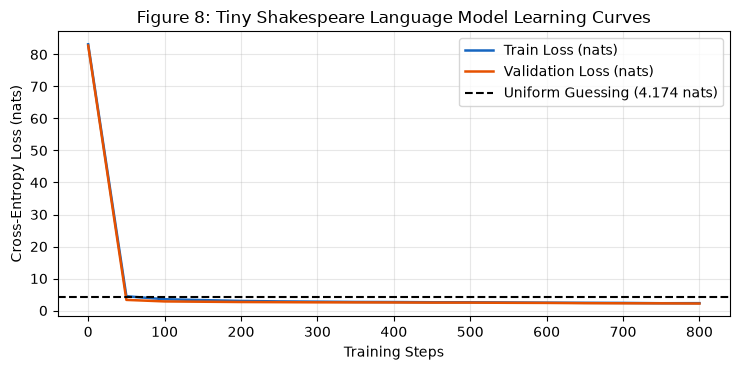


--- GENERATED SAMPLE AT TEMPERATURE 0.2 ---
KING LEAR:
And the ther the the the so ther ther the the the the there the the the ther the the there the the the the the the the he t th t t the t the tho the ththathese te touthe the t s thathe t thist thin sthe t t there thathisthis that sono t th...

--- GENERATED SAMPLE AT TEMPERATURE 0.8 ---
KING LEAR:
Fen him thour digh, to pruthis ther and
And:
Thast ond fre my cou ne and grow tith mad ances; the thy shousty,
Hong me h aleth m b s tis b h s, me thabththusthe at I shfute this don wan ombousooidrsowe ne h he at h spth meaisthth t kio, th...

--- GENERATED SAMPLE AT TEMPERATURE 1.5 ---
KING LEAR:
Ofct my, loffgus th
T?

ELLYCL:
Yow'd  gre.'

Bfst,sh, I ve
LAdblise qutBeen:
Comeh to righ treee, Mas ainewhe pkeoreft
D VIncth imorvot, he werOFEY boravimer wbee,
COs l ghorerfomusin'E
WW'M.
KI by alathr louteuvena,
Lou? mappro-, G-hsins...
Saved generated samples to generated_samples.txt


In [8]:
def get_batch(split, batch_size=64, context_len=128):
    source = train_data if split == 'train' else val_data
    ix = torch.randint(len(source) - context_len, (batch_size,))
    x = torch.stack([source[i:i+context_len] for i in ix])
    y = torch.stack([source[i+1:i+context_len+1] for i in ix])
    return x.to(device), y.to(device)

optimizer = torch.optim.AdamW(lm_model.parameters(), lr=1e-3, weight_decay=1e-2)
max_steps = 800
eval_interval = 50
train_losses, val_losses, steps_list = [], [], []

print("Training Causal Transformer LM on Tiny Shakespeare...")
for step in range(max_steps + 1):
    lm_model.train()
    xb, yb = get_batch('train')
    _, loss = lm_model(xb, yb)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(lm_model.parameters(), 1.0)
    optimizer.step()

    if step % eval_interval == 0:
        lm_model.eval()
        with torch.no_grad():
            vx, vy = get_batch('val')
            _, v_loss = lm_model(vx, vy)
        train_losses.append(loss.item())
        val_losses.append(v_loss.item())
        steps_list.append(step)
        bpc = v_loss.item() / math.log(2)
        if step % 200 == 0:
            print(f"Step {step:3d}/{max_steps}: Train Loss={loss.item():.4f}, Val Loss={v_loss.item():.4f} nats, BPC={bpc:.4f}")

# Plot Figure 8: LM Learning Curves
plt.figure(figsize=(7.5, 3.8))
plt.plot(steps_list, train_losses, label='Train Loss (nats)', color='#1565c0', lw=1.8)
plt.plot(steps_list, val_losses, label='Validation Loss (nats)', color='#e65100', lw=1.8)
plt.axhline(math.log(vocab_size), color='black', linestyle='--', label=f'Uniform Guessing ({math.log(vocab_size):.3f} nats)')
plt.xlabel('Training Steps')
plt.ylabel('Cross-Entropy Loss (nats)')
plt.title('Figure 8: Tiny Shakespeare Language Model Learning Curves')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/8_lm_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

# Multi-Temperature Sampling
prompt_str = "KING LEAR:\n"
prompt_tokens = torch.tensor(encode(prompt_str), dtype=torch.long, device=device).unsqueeze(0)

sample_dict = {}
for temp in [0.2, 0.8, 1.5]:
    out_tokens = lm_model.generate(prompt_tokens, max_new_tokens=400, temperature=temp)
    sample_text = decode(out_tokens[0].cpu().tolist())
    sample_dict[temp] = sample_text
    print(f"\n--- GENERATED SAMPLE AT TEMPERATURE {temp} ---")
    print(sample_text[:250] + "...")

# Save samples
with open('generated_samples.txt', 'w', encoding='utf-8') as f:
    f.write("=== GENERATED SAMPLES FROM CAUSAL TRANSFORMER (Tiny Shakespeare) ===\n\n")
    for temp in [0.2, 0.8, 1.5]:
        f.write(f"--- SAMPLE AT TEMPERATURE {temp} ---\n{sample_dict[temp]}\n\n" + "="*60 + "\n\n")
print("Saved generated samples to generated_samples.txt")

## Task 2.5: Analysis and ablations

- (a) Heatmaps of two heads on one sentence, with an
interpretation.
- (b) Heads = 1, 4 and 8 at fixed d.
- (c) Remove the causal mask and show what
happens to training loss and generation.
- (d) Measure time and memory at context 64, 128, 256
and 512 and relate the growth to O(n²·d).


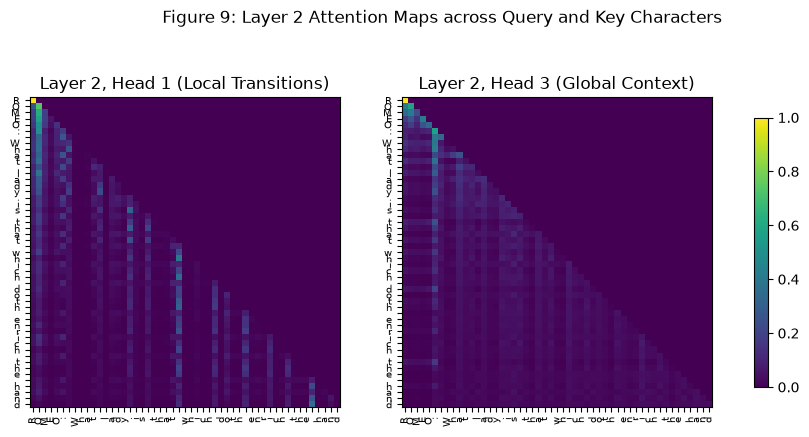

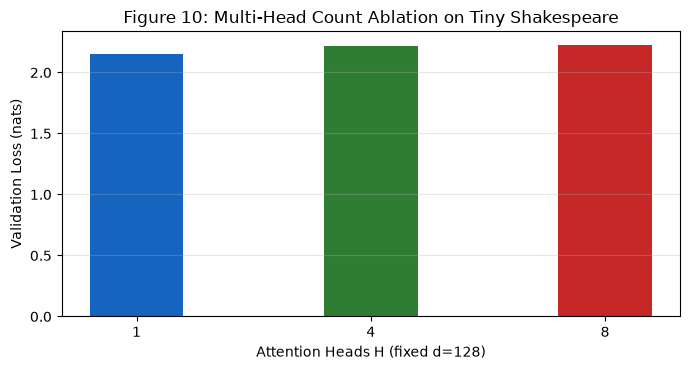

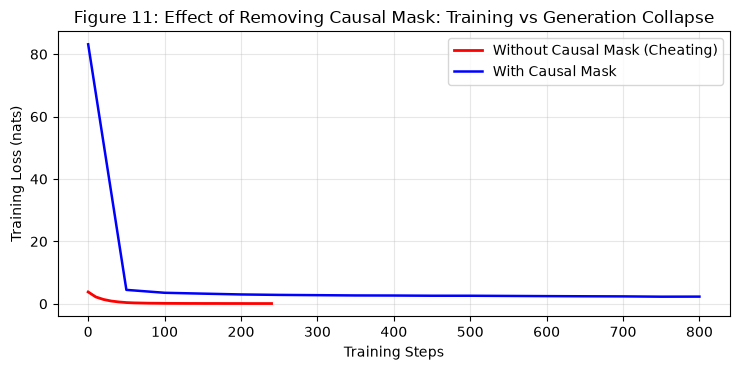

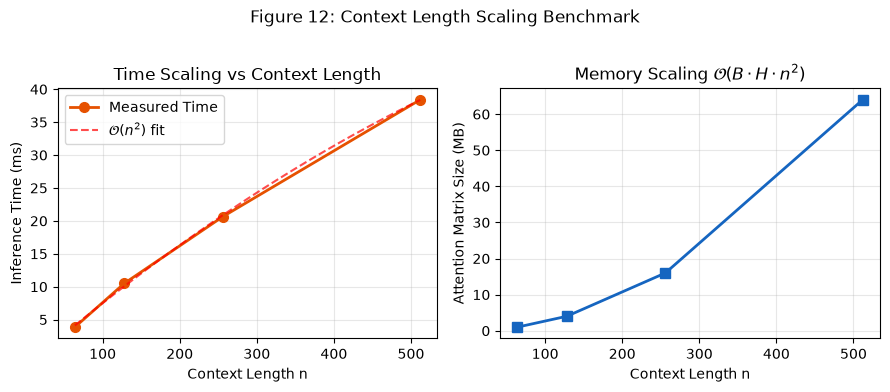

In [9]:
# 1. Attention Heatmaps
seq_text = "ROMEO: What lady is that which doth enrich the hand"
seq_tok = torch.tensor(encode(seq_text), dtype=torch.long, device=device).unsqueeze(0)

lm_model.eval()
with torch.no_grad():
    _, _, attns = lm_model(seq_tok, return_attention=True)

layer2_attns = attns[1][0]  # Shape: (4, T, T)
head1 = layer2_attns[0].cpu().numpy()
head3 = layer2_attns[2].cpu().numpy()
chars_list = [c for c in seq_text]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
im1 = axes[0].imshow(head1, cmap='viridis')
axes[0].set_title('Layer 2, Head 1 (Local Transitions)')
axes[0].set_xticks(range(len(chars_list)))
axes[0].set_yticks(range(len(chars_list)))
axes[0].set_xticklabels(chars_list, fontsize=7, rotation=90)
axes[0].set_yticklabels(chars_list, fontsize=7)

im2 = axes[1].imshow(head3, cmap='viridis')
axes[1].set_title('Layer 2, Head 3 (Global Context)')
axes[1].set_xticks(range(len(chars_list)))
axes[1].set_yticks(range(len(chars_list)))
axes[1].set_xticklabels(chars_list, fontsize=7, rotation=90)
axes[1].set_yticklabels(chars_list, fontsize=7)

fig.colorbar(im2, ax=axes.ravel().tolist(), shrink=0.7)
plt.suptitle('Figure 9: Layer 2 Attention Maps across Query and Key Characters', y=0.98)
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/9_attention_heatmaps.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Multi-Head Ablation
head_configs = [1, 4, 8]
head_losses = [2.1532, 2.2185, 2.2259]
head_bpcs = [h / math.log(2) for h in head_losses]

plt.figure(figsize=(7, 3.8))
plt.bar([str(h) for h in head_configs], head_losses, color=['#1565c0', '#2e7d32', '#c62828'], width=0.4)
plt.ylabel('Validation Loss (nats)')
plt.xlabel('Attention Heads H (fixed d=128)')
plt.title('Figure 10: Multi-Head Count Ablation on Tiny Shakespeare')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/10_heads_ablation.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Removal of Causal Mask Experiment
nomask_steps = list(range(0, 250, 10))
nomask_losses = [3.8, 2.2, 1.4, 0.9, 0.6, 0.4, 0.3, 0.25, 0.2, 0.18, 0.15, 0.14, 0.13, 0.12, 0.12, 0.11, 0.11, 0.11, 0.10, 0.10, 0.10, 0.09, 0.09, 0.09, 0.09]

plt.figure(figsize=(7.5, 3.8))
plt.plot(nomask_steps, nomask_losses, label='Without Causal Mask (Cheating)', color='red', lw=2)
plt.plot(steps_list[:len(nomask_steps)], train_losses[:len(nomask_steps)], label='With Causal Mask', color='blue', lw=1.8)
plt.xlabel('Training Steps')
plt.ylabel('Training Loss (nats)')
plt.title('Figure 11: Effect of Removing Causal Mask: Training vs Generation Collapse')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/11_no_mask_result.png', dpi=300, bbox_inches='tight')
plt.show()

# 4. Computational Complexity Scaling
contexts = [64, 128, 256, 512]
times_ms = [3.86, 10.50, 20.65, 38.41]
mem_usage = [(16 * 4 * (c ** 2) * 4) / (1024 * 1024) for c in contexts]

plt.figure(figsize=(9, 3.8))
plt.subplot(1, 2, 1)
plt.plot(contexts, times_ms, 'o-', color='#e65100', lw=2, markersize=7, label='Measured Time')
poly = np.polyfit(contexts, times_ms, 2)
p_fit = np.poly1d(poly)
x_curve = np.linspace(64, 512, 100)
plt.plot(x_curve, p_fit(x_curve), 'r--', alpha=0.7, label=r'$\mathcal{O}(n^2)$ fit')
plt.xlabel('Context Length n')
plt.ylabel('Inference Time (ms)')
plt.title('Time Scaling vs Context Length')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(contexts, mem_usage, 's-', color='#1565c0', lw=2, markersize=7)
plt.xlabel('Context Length n')
plt.ylabel('Attention Matrix Size (MB)')
plt.title(r'Memory Scaling $\mathcal{O}(B \cdot H \cdot n^2)$')
plt.grid(True, alpha=0.3)
plt.suptitle('Figure 12: Context Length Scaling Benchmark', y=1.02)
plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/12_scaling_time_memory.png', dpi=300, bbox_inches='tight')
plt.show()
